# Hydraulic cooler diagnosis: a multivariate statistics walkthrough

This notebook uses real UCI 447 measurements. It links all ten requested methods
to the actual diagnostic model. The accompanying PDF gives the full discussion.

**Main result:** temperature alone is already perfect on the stable holdout.
The joint model demonstrates a fallback when the complete TS2 sensor is unavailable.
**Main limitation:** recorded cooler condition and recording phase are perfectly confounded.

Run cells in order. Start Jupyter from this project folder or its `notebooks/` folder.
All outputs below were generated by executing these cells. No network is needed.

In [1]:
from pathlib import Path
import sys, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import linalg, stats
ROOT = Path.cwd()
if not (ROOT / 'src').exists():
    ROOT = ROOT.parent
assert (ROOT / 'src/statistics_core.py').exists(), 'Start inside the extracted project'
sys.path.insert(0, str(ROOT / 'src'))
from extract_features import CORE, LABELS
from statistics_core import (covariance, logdet, mardia, balanced_manova,
                             paired_hotelling, holm_adjust, box_m, covariance_lrt)
from analyze import numeric_mle, partial_regression
from predict import predict_frame
r = json.loads((ROOT / 'results/analysis.json').read_text())
d = pd.read_csv(ROOT / 'data/cycle_features.csv')
p = pd.read_csv(ROOT / 'data/matched_profiles.csv')
ORDER = [100, 20, 3]
def show_figure(name):
    image = plt.imread(ROOT / 'figures' / (name + '.png'))
    fig, ax = plt.subplots(figsize=(12, 6))
    ax.imshow(image); ax.axis('off'); fig.tight_layout()
    plt.show()
print('Cycles:', len(d), '| stable:', (d.unstable == 0).sum())
print('Matched profiles:', len(p), '| features:', CORE)

Cycles: 2205 | stable: 1449
Matched profiles: 144 | features: ['TS2_mean', 'TS2_slope', 'FS1_mean', 'PS2_std', 'EPS1_mean', 'VS1_mean']


## Data and experimental design

Cooler grades are 100 (full efficiency), 20 (reduced efficiency) and 3 (near failure).
A source flag of zero means stable conditions were reached.
All 48 valve × pump × accumulator settings occur in every cooler condition.
Averaging stable cycles inside each cell gives 144 profiles for matched inference.

The three cooler conditions occur in uninterrupted phases. Therefore matching settings
does not identify a causal cooler effect. Grouped diagnostic validation asks about
unseen settings **within this experiment**, not unseen rigs or campaigns.

unstable    0    1
cooler            
3         480  252
20        480  252
100       489  252
Development settings: 36
Holdout settings: 12


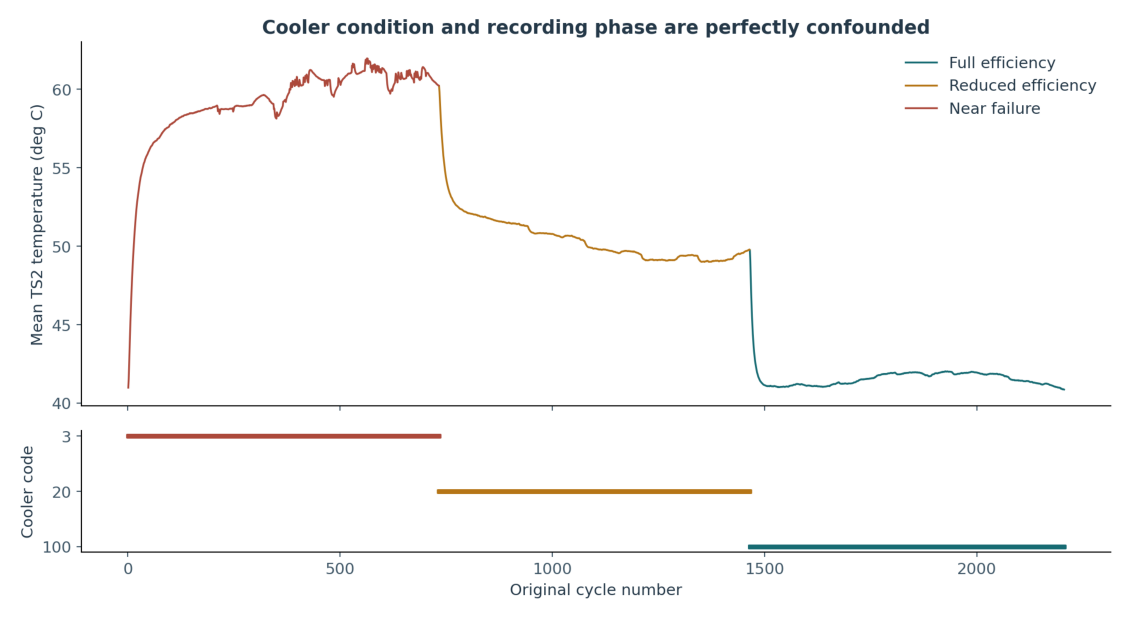

In [2]:
print(d.groupby(['cooler', 'unstable']).size().unstack().to_string())
print('Development settings:', len(r['split']['development_settings']))
print('Holdout settings:', len(r['split']['test_settings']))
assert not set(r['split']['development_settings']) & set(r['split']['test_settings'])
show_figure('01_experiment_order')

## 1. Mean vector

Each mean vector is a six-number condition fingerprint:
$$\bar{\mathbf{x}}_k=\frac{1}{48}\sum_{s=1}^{48}\mathbf{x}_{sk}.$$

The raw table keeps physical units. The plot uses one common scale across all
profiles so coordinates with different units can be compared visually.
Its error bars are between-setting standard deviations, not confidence intervals.

         TS2_mean  TS2_slope  FS1_mean    PS2_std    EPS1_mean  VS1_mean
cooler                                                                  
100     41.642717   0.002590  6.529206  47.322103  2552.379908  0.545579
20      49.722976   0.004312  6.488710  46.610752  2471.899254  0.614311
3       60.186360   0.001397  4.918689  51.196265  2504.401366  0.696318


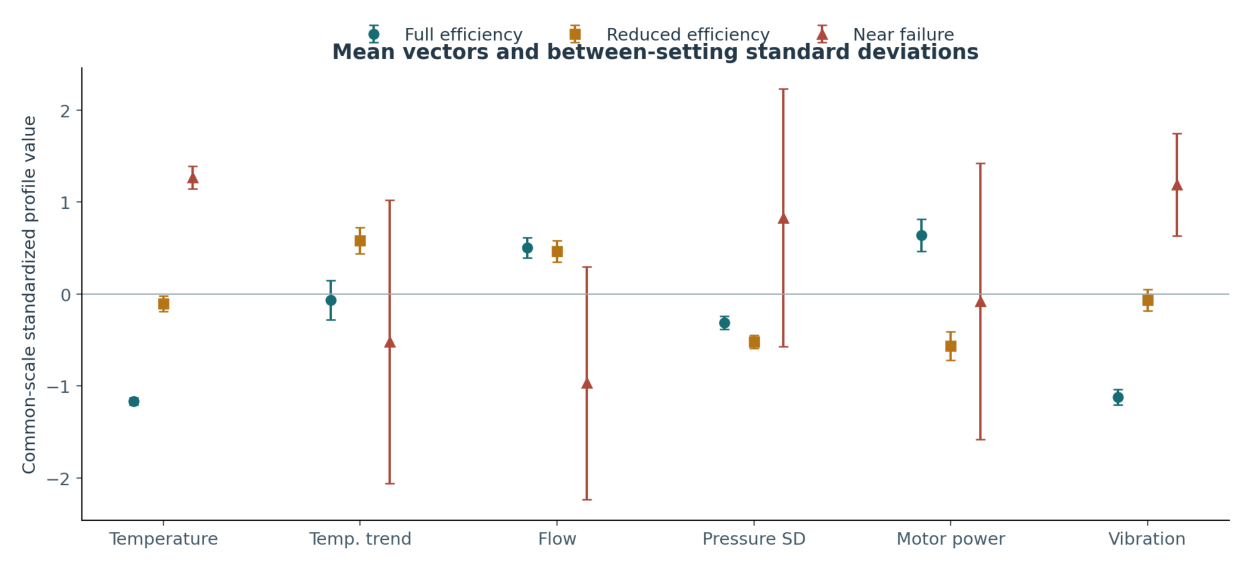

In [3]:
means = p.groupby('cooler')[CORE].mean().reindex(ORDER)
print(means.round(6).to_string())
# This common reference scale is descriptive; it is not the diagnostic training scaler.
reference_mean = p[CORE].mean().to_numpy()
reference_sd = p[CORE].std(ddof=0).to_numpy()
z = (p[CORE].to_numpy() - reference_mean) / reference_sd
groups = [z[p.cooler.to_numpy() == k] for k in ORDER]
show_figure('03_mean_vectors')

## 2. Covariance and correlation

$$S=\frac{1}{n-1}\sum_i(\mathbf{x}_i-\bar{\mathbf{x}})(\mathbf{x}_i-\bar{\mathbf{x}})^T,
\qquad r_{ij}=\frac{s_{ij}}{\sqrt{s_{ii}s_{jj}}}.$$

The diagonal stores variance. Off-diagonal entries store linear co-variation.
Correlation is dimensionless; zero correlation does not generally imply independence.

Full efficiency: common-scale covariance
           TS2_mean  TS2_slope  FS1_mean  PS2_std  EPS1_mean  VS1_mean
TS2_mean     0.0015    -0.0025    0.0003  -0.0002    -0.0022   -0.0011
TS2_slope   -0.0025     0.0453    0.0046   0.0040     0.0005    0.0009
FS1_mean     0.0003     0.0046    0.0120   0.0020    -0.0162    0.0008
PS2_std     -0.0002     0.0040    0.0020   0.0054    -0.0021    0.0015
EPS1_mean   -0.0022     0.0005   -0.0162  -0.0021     0.0310   -0.0029
VS1_mean    -0.0011     0.0009    0.0008   0.0015    -0.0029    0.0067


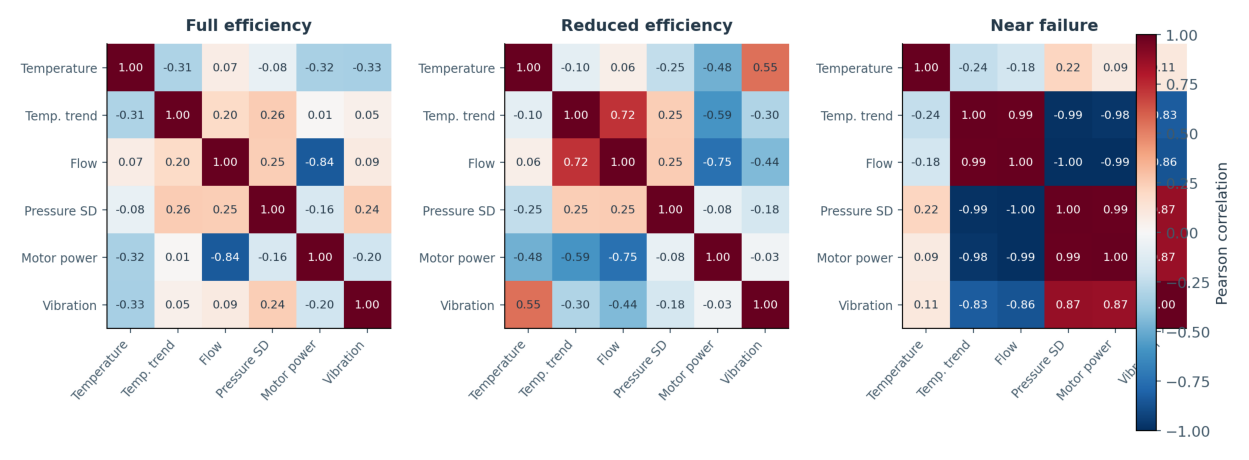

In [4]:
S = covariance(groups[0])
R = S / np.sqrt(np.outer(np.diag(S), np.diag(S)))
print('Full efficiency: common-scale covariance')
print(pd.DataFrame(S, index=CORE, columns=CORE).round(4).to_string())
np.testing.assert_allclose(R, np.corrcoef(groups[0], rowvar=False), atol=1e-12)
show_figure('04_correlation_matrices')

## 3. Generalized variance

$$GV=|S|=\prod_j\lambda_j,\qquad SGV=|S|^{1/p}.$$

Determinants combine spread along every direction. We compare groups on the same
global coordinate scale. Per-group standardization would instead compare determinants
of correlation matrices, which is a different quantity.

         condition     log GV           GV      SGV
   Full efficiency -29.983894 9.509559e-14 0.006756
Reduced efficiency -29.658426 1.316768e-13 0.007133
      Near failure -19.157258 4.787500e-09 0.041054


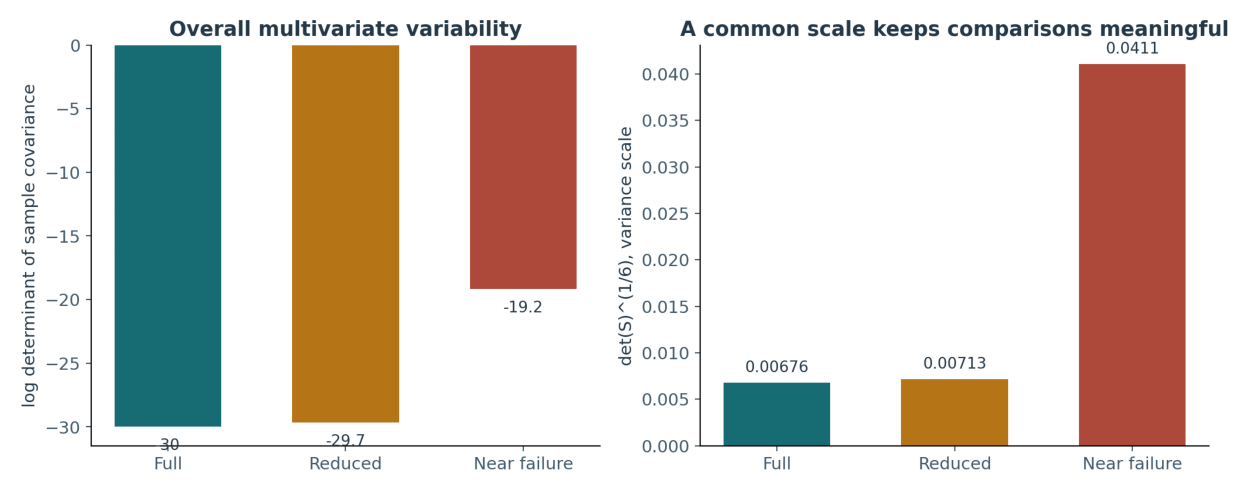

In [5]:
rows = []
for k, x in zip(ORDER, groups):
    value = logdet(covariance(x))
    rows.append([LABELS[k], value, np.exp(value), np.exp(value / 6)])
print(pd.DataFrame(rows, columns=['condition', 'log GV', 'GV', 'SGV']).to_string(index=False))
show_figure('05_generalized_variance')

## 4. Skewness, kurtosis and distribution checks

Define $D_{ij}=(x_i-\bar x)^T\hat\Sigma_{ML}^{-1}(x_j-\bar x)$.
Mardia's measures are $b_{1,p}=n^{-2}\sum_{i,j}D_{ij}^3$ and
$b_{2,p}=n^{-1}\sum_iD_{ii}^2$.

Check within each condition. A pooled mixture of three separated means need not be
Gaussian even if its separate components are. The population Gaussian kurtosis target
is p(p+2)=48, but fitted finite-n behaviour differs, so the pipeline also uses a
simulated Gaussian reference at n=48, p=6. Chi-square Q-Q plots are approximate.

         condition  skewness  kurtosis  skew MC p  kurt MC p
   Full efficiency   9.42783  42.46286      0.027      0.104
Reduced efficiency   8.18044  43.57902      0.099      0.291
      Near failure  13.63089  44.16451      0.001      0.426
Marginal excess kurtosis, full efficiency: [-0.963 -1.313 -1.463 -0.934 -0.175 -0.277]


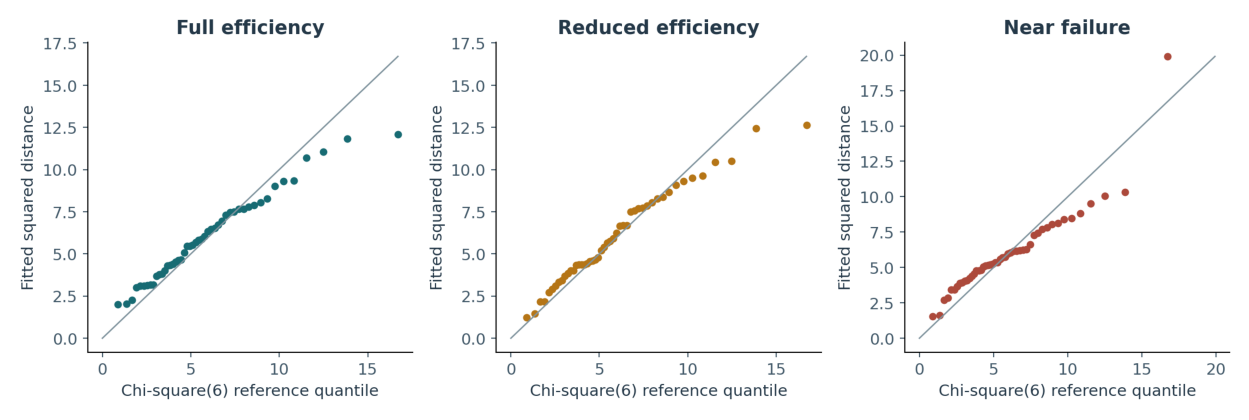

In [6]:
rows = []
for k, x, saved in zip(ORDER, groups, r['distribution_checks']['groups']):
    m = mardia(x)
    rows.append([LABELS[k], m['skewness'], m['kurtosis'], saved['skew_p_mc'], saved['kurtosis_p_mc']])
print(pd.DataFrame(rows, columns=['condition', 'skewness', 'kurtosis', 'skew MC p', 'kurt MC p']).round(5).to_string(index=False))
print('Marginal excess kurtosis, full efficiency:', stats.kurtosis(groups[0], bias=False).round(3))
show_figure('07_multivariate_qq')

## 5. Maximum likelihood estimation

For an independent Gaussian working sample,
$$\hat\mu=\bar x,\qquad\hat\Sigma_{ML}=\frac{1}{n}\sum_i(x_i-\bar x)(x_i-\bar x)^T
=\frac{n-1}{n}S.$$

The analytical MLE is checked by BFGS numerical optimization for two full-efficiency
coordinates (TS2 mean and EPS1 mean). The optimizer uses means, log standard deviations
and atanh(correlation), on the common global standardized scale. Positive variances
and a valid correlation are guaranteed by this parameterization.

Analytical log likelihood: 106.43148000168901
Numerical log likelihood: 106.43148000168904
Converged: True
Maximum parameter gap: 3.6732616948143004e-11


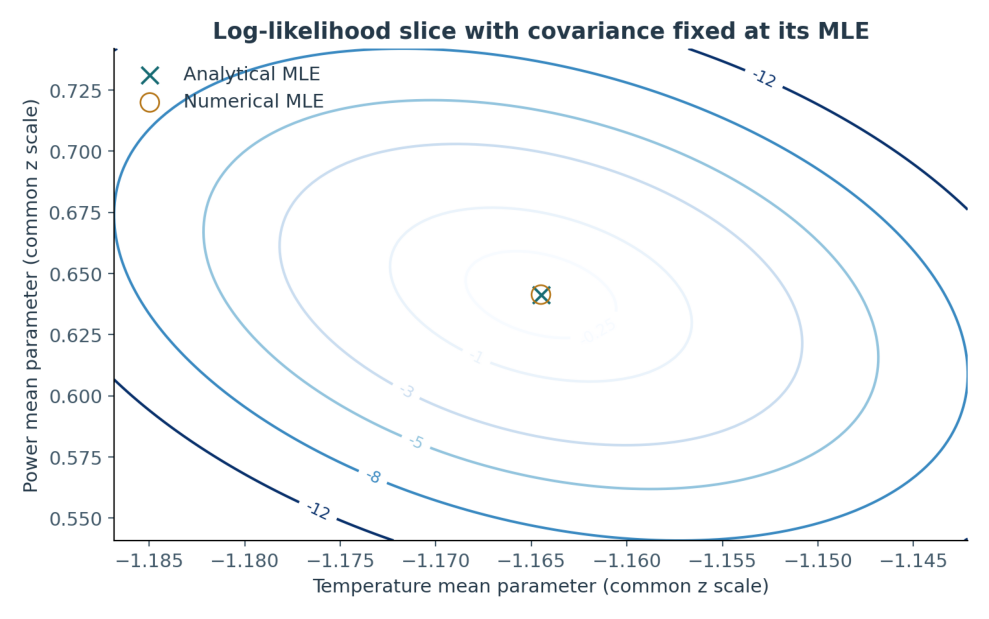

In [7]:
Sigma_ml = covariance(groups[0], mle=True)
np.testing.assert_allclose(Sigma_ml, 47 / 48 * covariance(groups[0]))
mle = numeric_mle(groups[0])
print('Analytical log likelihood:', mle['analytic_loglik'])
print('Numerical log likelihood:', mle['numeric_loglik'])
print('Converged:', mle['optimizer_success'])
print('Maximum parameter gap:', mle['max_parameter_gap'])
assert mle['optimizer_success'] and mle['max_parameter_gap'] < 1e-6
show_figure('08_MLE_likelihood')

## 6. MANOVA with matched setting effects

$$Y_{sk}=a_s+\tau_k+\varepsilon_{sk}.$$

A setting-specific intercept accounts for the recorded nuisance setting baseline.
H measures the condition contrast; E measures additive-model residuals. The generalized
eigenvalues solve $Hv=\lambda Ev$. Roy is the largest root, and
Wilks is $\prod_j(1+\lambda_j)^{-1}$.

The usual iid Gaussian p-values and the setting-clustered wild sensitivities answer
related but assumption-dependent questions. None resolves cooler/phase confounding.

{'roy': 251.2528906736278, 'wilks': 0.0007911232041839504, 'pillai': 1.7964726091874414, 'hotelling_lawley': 255.26383670603275, 'df_h': 2, 'df_e': 94}


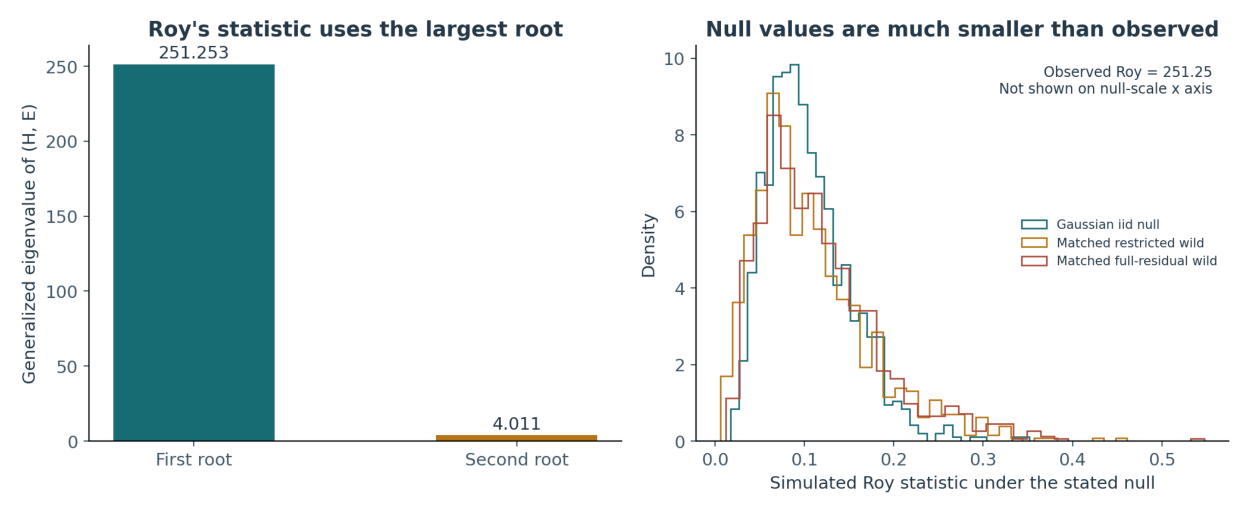

In [8]:
settings = sorted(p.setting.unique())
indexed = p.set_index(['setting', 'cooler'])
raw_y = np.array([[indexed.loc[(s, k), CORE].to_numpy(dtype=float) for k in ORDER] for s in settings])
Y = (raw_y - reference_mean) / reference_sd
mv = balanced_manova(Y)
print({k: mv[k] for k in ['roy', 'wilks', 'pillai', 'hotelling_lawley', 'df_h', 'df_e']})
np.testing.assert_allclose(mv['roy'], r['manova']['roy'], rtol=1e-9)
show_figure('09_MANOVA_simulation')

## 7. Paired Hotelling's T²

For each condition pair, compute 48 difference vectors $d_s$:
$$T^2=b\bar d^TS_d^{-1}\bar d,\qquad
F=\frac{b-p}{p(b-1)}T^2\sim F_{p,b-p}.$$

Here b=48 and p=6. This F reference requires independent Gaussian difference vectors.
Holm adjustment handles three planned comparisons. Sign-flip sensitivity needs a
symmetry/exchangeability assumption. A mean confidence region is not a future-cycle
prediction region.

    contrast           T2           F        iid p   Holm iid p
20 minus 100 17168.874473 2557.066411 3.634112e-52 7.268223e-52
 3 minus 100 29407.022783 4379.769351 4.611206e-57 1.383362e-56
  3 minus 20  5347.417704  796.423913 1.377481e-41 1.377481e-41


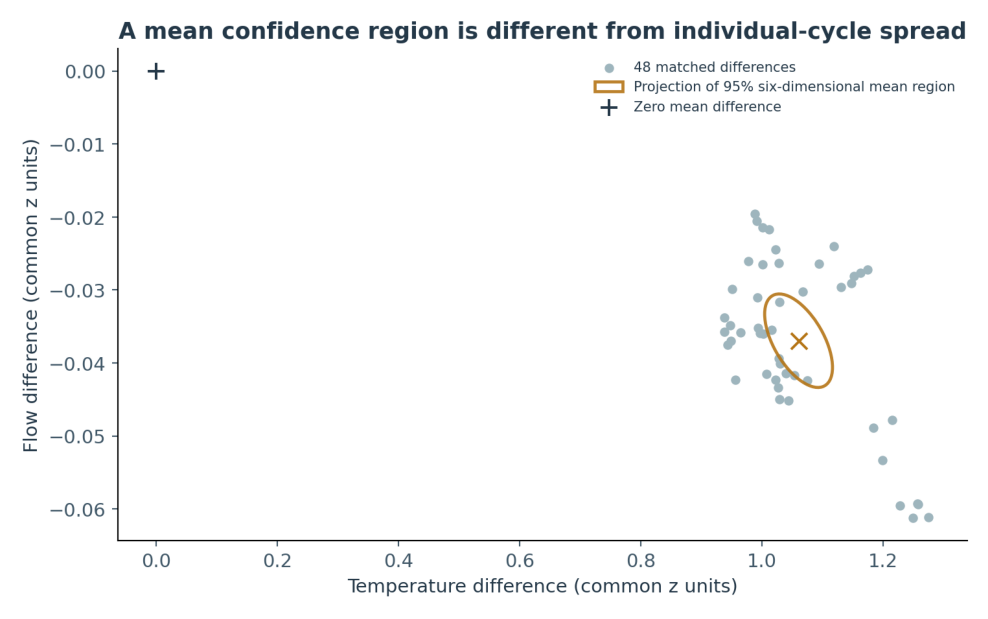

In [9]:
tests = []
for a, b in [(0, 1), (0, 2), (1, 2)]:
    h = paired_hotelling(Y[:, b] - Y[:, a])
    tests.append([f'{ORDER[b]} minus {ORDER[a]}', h['T2'], h['F'], h['p_iid']])
adjusted = holm_adjust([row[3] for row in tests])
for row, adj in zip(tests, adjusted): row.append(adj)
print(pd.DataFrame(tests, columns=['contrast', 'T2', 'F', 'iid p', 'Holm iid p']).to_string(index=False))
show_figure('11_Hotelling_region')

## 8. Covariance equality tests

Box's M uses unbiased sample covariance matrices and residual degrees of freedom.
The separate Gaussian likelihood-ratio calculation uses ML covariance divisors n.
Both have 42 conventional chi-square degrees of freedom for g=3, p=6.

Both strongly reject covariance equality under their references. The matched Gaussian
covariance-null simulation assumes a 50% shared normal component: a sensitivity model,
not an estimated law of actual dependence. Prediction selection is evaluated separately.

Box M: 732.2726494029262 | corrected chi2: 688.2522064465868 | df: 42 | iid p: 8.357598112894397e-118
Gaussian ML covariance LRT: {'LR': 747.852918539163, 'df': 42, 'p_iid': 5.002713929377259e-130}


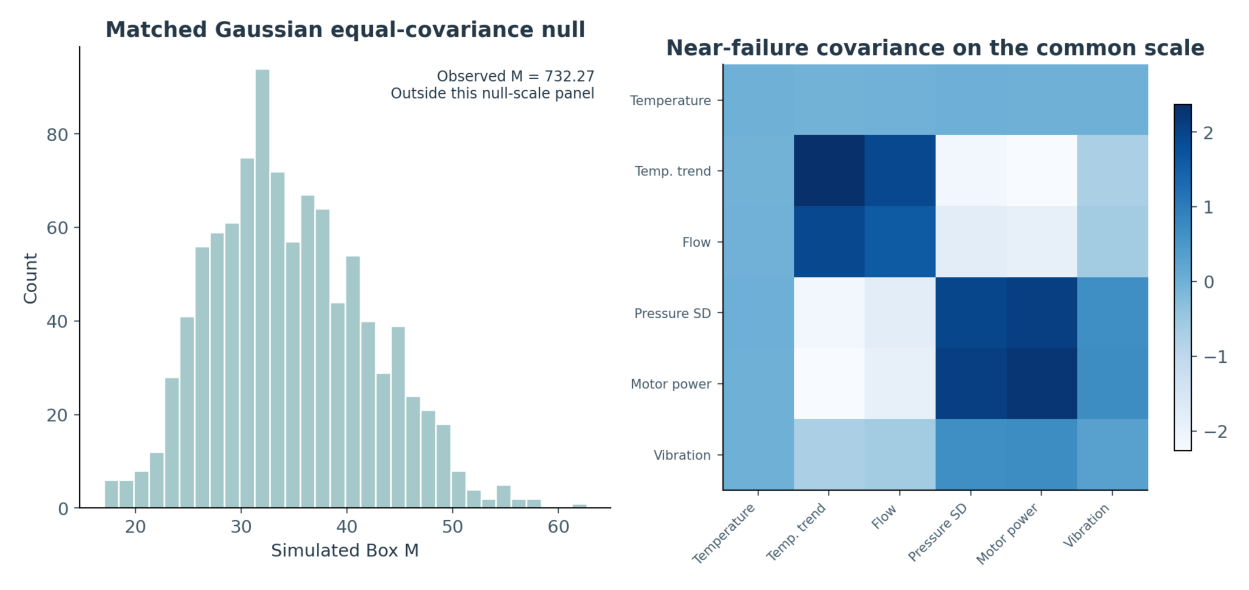

In [10]:
bm = box_m(groups)
lr = covariance_lrt(groups)
print('Box M:', bm['M'], '| corrected chi2:', bm['chi2'], '| df:', bm['df'], '| iid p:', bm['p_iid'])
print('Gaussian ML covariance LRT:', lr)
assert bm['df'] == lr['df'] == 42
show_figure('12_covariance_equality')

## 9. Partial correlation and regression

Regress each profile feature on categorical cooler/phase, valve, pump and accumulator
indicators. Let R be the matrix of residuals. Partial correlation here is simply
$r_{ij\cdot C}=corr(R_i,R_j)$.

Adjustment asks about association beyond these recorded factors. It cannot account for
unmeasured drift or distinguish cooler from phase. The explanatory regression's R² is
in-sample and is not diagnostic validation performance.

Recorded-factor adjustment: ['cooler/phase', 'valve', 'pump', 'accumulator']
Explanatory temperature R2 (in sample): 0.9928465441761813
           TS2_mean  TS2_slope  FS1_mean  PS2_std  EPS1_mean  VS1_mean
TS2_mean      1.000     -0.317    -0.279    0.245      0.148     0.206
TS2_slope    -0.317      1.000     0.970   -0.970     -0.950    -0.775
FS1_mean     -0.279      0.970     1.000   -0.999     -0.987    -0.823
PS2_std       0.245     -0.970    -0.999    1.000      0.991     0.820
EPS1_mean     0.148     -0.950    -0.987    0.991      1.000     0.797
VS1_mean      0.206     -0.775    -0.823    0.820      0.797     1.000


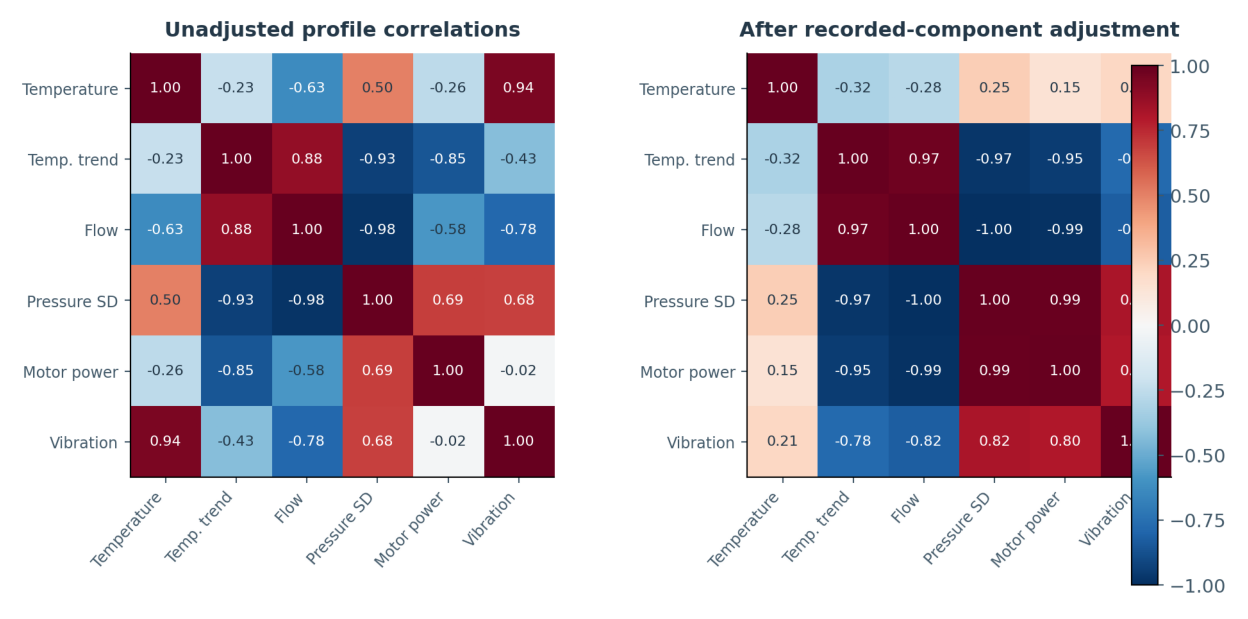

In [11]:
adjusted = partial_regression(p, z)
print('Recorded-factor adjustment:', adjusted['adjustment'])
print('Explanatory temperature R2 (in sample):', adjusted['temperature_R2_in_sample'])
print(pd.DataFrame(adjusted['adjusted_correlation'], index=CORE, columns=CORE).round(3).to_string())
show_figure('13_partial_correlations')

## 10. Simulation and resampling

Saved null draws are reproducible from the fixed seed and the full analysis script.
$$p_{MC}=\frac{1+\#\{T_b\geq T_{obs}\}}{B+1}.$$

The restricted wild reference uses null residuals and one Rademacher sign per matched
setting across all three conditions and six coordinates. The full-residual null-centred
variant is labelled separately. Gaussian simulation assumes its specified normal null.
Block lengths 1, 4 and 8 are sensitivity analyses, not a proof of time independence.

         reference   B  95% critical  MC p
 gaussian_iid_null 999      0.187403 0.001
   wild_restricted 999      0.242871 0.001
wild_full_residual 999      0.258243 0.001
Empirical holdout interval: intact [1.0, 1.0]
Empirical holdout interval: TS2_unavailable [1.0, 1.0]
A perfect empirical interval is not proof of zero future error.
Assumption-dependent iid-setting failure upper bound: 0.22092219194555585


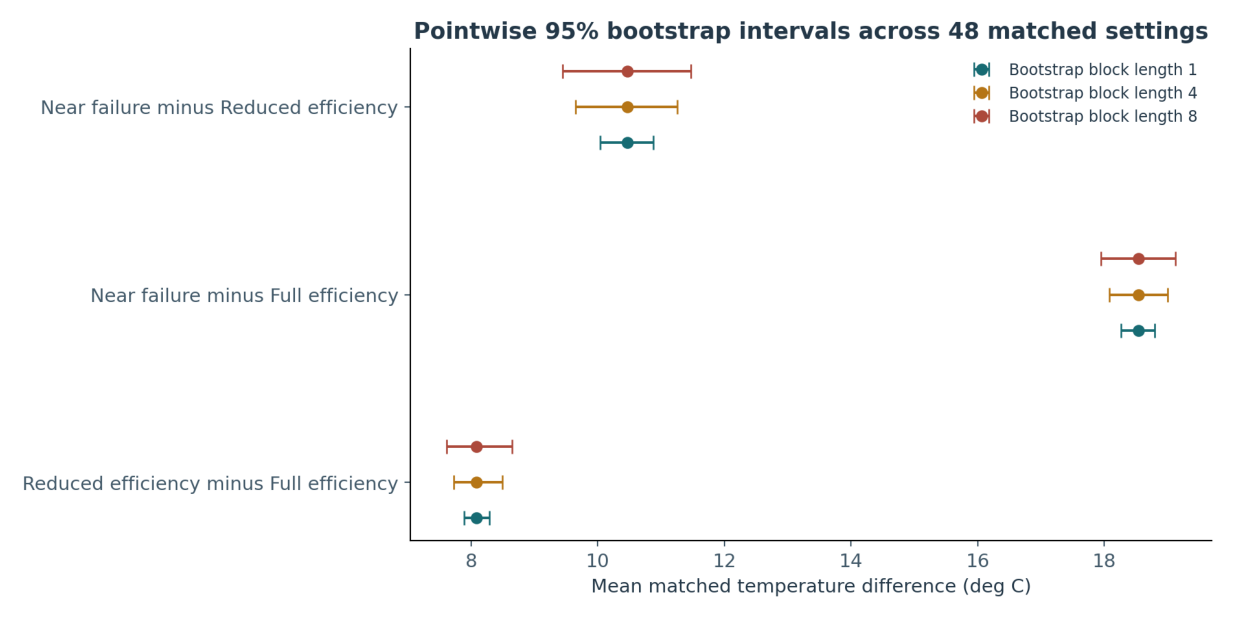

In [12]:
rows = []
for name, sim in r['manova']['resampling'].items():
    draws = np.array(sim['roy_samples'])
    p_mc = (1 + np.sum(draws >= r['manova']['roy'])) / (len(draws) + 1)
    assert p_mc == sim['p_mc']
    rows.append([name, len(draws), np.quantile(draws, .95), p_mc])
print(pd.DataFrame(rows, columns=['reference', 'B', '95% critical', 'MC p']).to_string(index=False))
for scenario, boot in r['holdout_block_bootstrap'].items():
    print('Empirical holdout interval:', scenario, [boot['lower'], boot['upper']])
print('A perfect empirical interval is not proof of zero future error.')
print('Assumption-dependent iid-setting failure upper bound:', 1 - .05 ** (1 / 12))
show_figure('10_matched_contrast_intervals')

## Final model and honest validation

Six-fold grouped development cross-validation selects the covariance family and alpha.
Its objective averages intact and complete-TS2-outage log loss. The selected shared
covariance has alpha=0. The final 12 settings never enter fitting or selection.

With observed coordinates O, the Gaussian score uses the exact marginal
$N(\mu_{k,O},\Sigma_{k,OO})$. Dropping both TS2 coordinates is different from inserting
zero measurements. With no observed input, posterior probabilities reduce to priors.

      model  alpha  intact BA  outage BA
temperature    0.0        1.0   0.333333
   diagonal    0.0        1.0   0.994444
     shared    0.0        1.0   1.000000
       full    0.0        1.0   0.997222
Selected: shared
 cycle_id predicted_condition  observed_coordinates
      212        Near failure                     4
      213        Near failure                     4
      944  Reduced efficiency                     4
      945  Reduced efficiency                     4
     1676     Full efficiency                     4
     1677     Full efficiency                     4


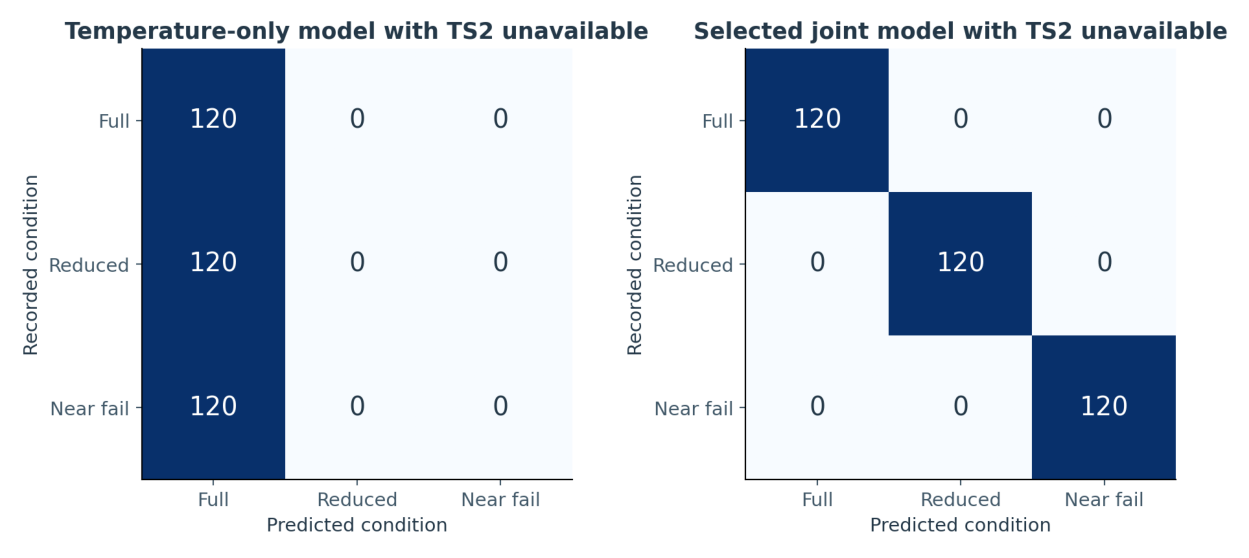

In [13]:
rows = []
for name, result in r['predictive_results'].items():
    rows.append([name, r['models'][name]['alpha'], result['intact']['balanced_accuracy'], result['TS2_unavailable']['balanced_accuracy']])
print(pd.DataFrame(rows, columns=['model', 'alpha', 'intact BA', 'outage BA']).to_string(index=False))
print('Selected:', r['selected_model'])
sample = pd.read_csv(ROOT / 'data/sample_inputs.csv')
print(predict_frame(sample, without_temperature=True)[['cycle_id', 'predicted_condition', 'observed_coordinates']].to_string(index=False))
show_figure('15_outage_confusion')

## Stress results and conclusion

Transition cycles are a separate evaluation set: 266 cycles from held-out settings,
never used for selection. Input-offset simulation changes TS2 mean only; it does
not simulate the physical response of the rig. These stress checks expose limits
hidden by a perfect stable holdout.

The defensible conclusion is an explainable, mathematically checked diagnostic
prototype with a demonstrated fallback in this experiment. The next study needs
repeated randomized cooler campaigns across several rigs and external validation.

Transition ordinary accuracy: 0.8721804511278195
Transition balanced accuracy: 0.948948948948949
Transition confusion matrix, true rows / predicted columns [100,20,3]:
[[ 22   0   0]
 [  0  22   0]
 [  6  28 188]]


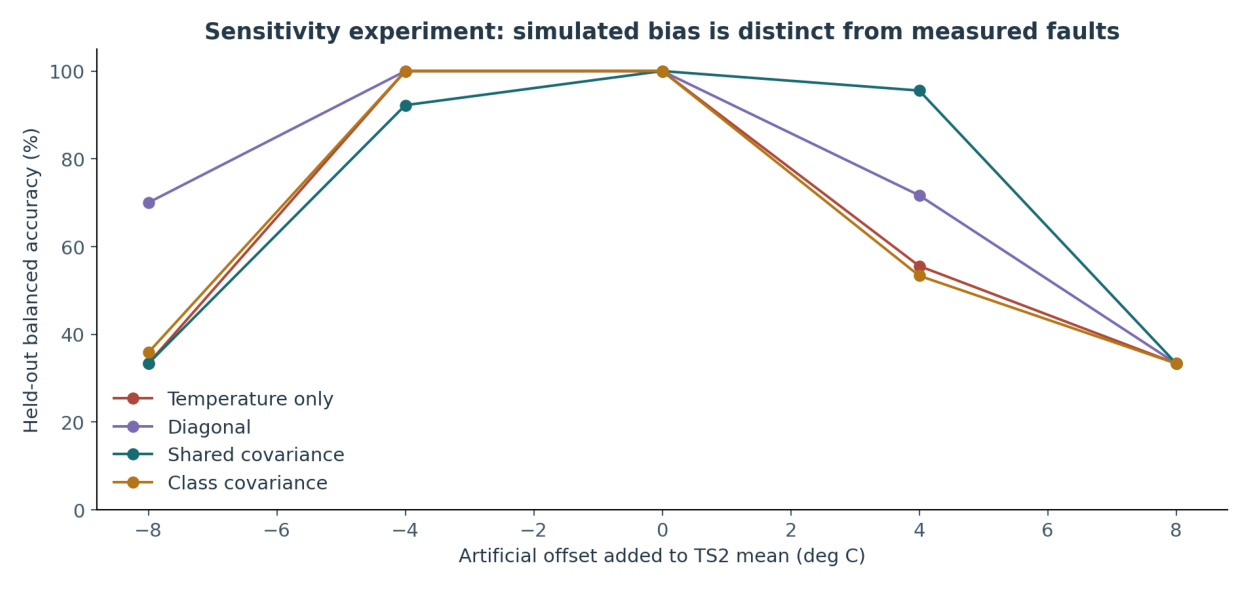

In [14]:
print('Transition ordinary accuracy:', r['transition_stress']['accuracy'])
print('Transition balanced accuracy:', r['transition_stress']['balanced_accuracy'])
print('Transition confusion matrix, true rows / predicted columns [100,20,3]:')
print(np.array(r['transition_stress']['confusion']))
show_figure('16_sensor_bias_simulation')

## References and next steps

Dataset: Helwig, Pignanelli & Schütze, UCI 447, DOI [10.24432/C5CW21](https://doi.org/10.24432/C5CW21), CC BY 4.0.
Original paper: DOI [10.1109/I2MTC.2015.7151267](https://doi.org/10.1109/I2MTC.2015.7151267).
Mardia (1970): DOI [10.1093/biomet/57.3.519](https://doi.org/10.1093/biomet/57.3.519).
Mathematical references and software links are listed in the PDF report.

- Open `../dist/index.html` for the interactive project.
- Read `../PRESENTATION_GUIDE.md` for a simple explanation and viva practice.
- Run `python run_project.py --extract` from the project root to regenerate from all original sensor matrices.
- Run `python run_project.py --tests-only` for the supplied mathematical and integrity checks.